# 5b) Debug Core/Substituent Split

Focused debug notebook for inspecting how the current functions in `5a-Core_Ring_Map_Functions.ipynb` split a ligand into coordination core and substituent fragments.

Current example: `ACAHUJ02`, to diagnose why the visualized substituent fragment appears to gain additional hydrogens.

In [1]:
%run ./5a-Core_Ring_Map_Functions.ipynb

In [2]:
project_path = Path('/Users/sergivela/Documents/SCOPE/Database_SCO')
root_path = project_path / 'Analysis/1-Analyse_Database'
outputs_path = root_path / 'Outputs'
env_path = project_path / 'Data/scope_env_atlas.npy'
thermo_csv_path = outputs_path / 'unique_thermodynamic_data.csv'

env = scope.read_write.load_binary(str(env_path))
debug_refcodes = ['ACAHUJ02']

In [3]:
systems = []
failed_loads = []
selected_refcodes = {refcode[:6].upper() for refcode in debug_refcodes}

for row in read_csv(thermo_csv_path):
    if row['refcode'].upper() not in selected_refcodes:
        continue

    system_path = resolve_system_path(project_path, row['path'])
    try:
        system = scope.read_write.load_binary(str(system_path))
        system.set_paths_from_environment(env)
        systems.append(system)
    except Exception as exc:
        failed_loads.append((row['refcode'], str(system_path), repr(exc)))

if not systems:
    raise ValueError(f'No systems loaded for {sorted(selected_refcodes)}; failures: {failed_loads}')

system = systems[0]
hs_ref_mol = get_hs_ref_mol(system)
ligand = hs_ref_mol.ligands[0]
lig_mol, smiles = get_rdkit_info(ligand)
donor_atoms = get_metal_bound_ligand_atoms(ligand)
core_atoms, subs_atoms = split_core_substituent(ligand, mols=False)
core_mol, subs_mol = split_core_substituent(ligand, mols=True)
weights, lig_distances = get_weights(ligand)

print('failed_loads:', failed_loads)
print('refcode:', system.refcode)
print('ligand smiles:', smiles)
print('ligand atoms:', lig_mol.GetNumAtoms())
print('core_atoms:', core_atoms)
print('subs_atoms:', subs_atoms)
print('core family:', core_family_label(core_mol))
print('core atoms in mol:', core_mol.GetNumAtoms())
print('subs atoms in mol:', subs_mol.GetNumAtoms())

failed_loads: []
refcode: ACAHUJ02
ligand smiles: [H]C(=Nc1c([H])c([H])c(OC([H])([H])[H])c([H])c1[H])c1nc([H])c([H])n1[H]
ligand atoms: 26
core_atoms: [ 0  4  5 18 19 20 21 22 23 24 25]
subs_atoms: [ 1  2  3  6  7  8  9 10 11 12 13 14 15 16 17]
core family: hybrid[scaffold=1x[C3N2];sites=C3N2:donors=1:attachments=1;nonring_degrees=N2]
core atoms in mol: 11
subs atoms in mol: 15


## Atom Tables

The table compares parent-ligand atom properties with the atoms that survive in the substituent fragment. If hydrogens are being added implicitly, the atom count can still look right while the drawing shows extra H labels at cut points.

In [4]:
def atom_table(mol, atom_indices=None, label='mol'):
    if atom_indices is None:
        atom_indices = list(range(mol.GetNumAtoms()))
    rows = []
    ring_atoms = {idx for ring in mol.GetRingInfo().AtomRings() for idx in ring}
    for local_row, atom_idx in enumerate(atom_indices):
        atom = mol.GetAtomWithIdx(atom_idx)
        metal_connected = atom.HasProp('_MetalDonor') and atom.GetBoolProp('_MetalDonor')
        connectivity_used = metal_connected and (not ring_atoms or atom_idx not in ring_atoms)
        rows.append({
            'table': label,
            'row': local_row,
            'atom_idx': atom_idx,
            'symbol': atom.GetSymbol(),
            'is_aromatic': atom.GetIsAromatic(),
            'formal_charge': atom.GetFormalCharge(),
            'explicit_Hs': atom.GetNumExplicitHs(),
            'implicit_Hs': atom.GetNumImplicitHs(),
            'no_implicit': atom.GetNoImplicit(),
            'degree': atom.GetDegree(),
            'total_degree': atom.GetTotalDegree(),
            'metal_connected': metal_connected,
            'effective_connectivity': atom.GetIntProp('_LigandEffectiveDegree') if metal_connected else None,
            'connectivity_used_in_label': connectivity_used,
            'neighbors': [nbr.GetIdx() for nbr in atom.GetNeighbors()],
        })
    return pd.DataFrame(rows)

parent_table = atom_table(lig_mol, label='parent ligand')
parent_table['in_core'] = parent_table['atom_idx'].isin(core_atoms)
parent_table['in_substituent'] = parent_table['atom_idx'].isin(subs_atoms)
display(parent_table)

display(atom_table(core_mol, label='core fragment'))
display(atom_table(subs_mol, label='substituent fragment'))

,table,row,atom_idx,symbol,is_aromatic,formal_charge,explicit_Hs,implicit_Hs,no_implicit,degree,total_degree,metal_connected,effective_connectivity,connectivity_used_in_label,neighbors,in_core,in_substituent
0,parent ligand,0,0,N,False,0,0,0,False,2,2,0,None,0,"[1, 4]",True,False
1,parent ligand,1,1,C,True,0,0,0,False,3,3,0,None,0,"[0, 2, 6]",False,True
2,parent ligand,2,2,C,True,0,0,0,False,3,3,0,None,0,"[1, 3, 10]",False,True
3,parent ligand,3,3,H,False,0,0,0,False,1,1,0,None,0,[2],False,True
4,parent ligand,4,4,C,False,0,0,0,False,3,3,0,None,0,"[0, 5, 19]",True,False
5,parent ligand,5,5,H,False,0,0,0,False,1,1,0,None,0,[4],True,False
6,parent ligand,6,6,C,True,0,0,0,False,3,3,0,None,0,"[1, 7, 12]",False,True
7,parent ligand,7,7,H,False,0,0,0,False,1,1,0,None,0,[6],False,True
8,parent ligand,8,8,O,False,0,0,0,False,2,2,0,None,0,"[9, 14]",False,True
9,parent ligand,9,9,C,True,0,0,0,False,3,3,0,None,0,"[8, 10, 12]",False,True


,table,row,atom_idx,symbol,is_aromatic,formal_charge,explicit_Hs,implicit_Hs,no_implicit,degree,total_degree,metal_connected,effective_connectivity,connectivity_used_in_label,neighbors
0,core fragment,0,0,N,False,0,0,0,True,1,1,True,2.0,True,[1]
1,core fragment,1,1,C,False,0,0,0,True,3,3,0,NaN,0,"[0, 2, 4]"
2,core fragment,2,2,H,False,0,0,0,True,1,1,0,NaN,0,[1]
3,core fragment,3,3,N,True,0,0,0,True,2,2,True,2.0,False,"[4, 7]"
4,core fragment,4,4,C,True,0,0,0,True,3,3,0,NaN,0,"[1, 3, 5]"
5,core fragment,5,5,N,True,0,0,0,True,3,3,0,NaN,0,"[4, 6, 9]"
6,core fragment,6,6,H,False,0,0,0,True,1,1,0,NaN,0,[5]
7,core fragment,7,7,C,True,0,0,0,True,3,3,0,NaN,0,"[3, 8, 9]"
8,core fragment,8,8,H,False,0,0,0,True,1,1,0,NaN,0,[7]
9,core fragment,9,9,C,True,0,0,0,True,3,3,0,NaN,0,"[5, 7, 10]"


,table,row,atom_idx,symbol,is_aromatic,formal_charge,explicit_Hs,implicit_Hs,no_implicit,degree,total_degree,metal_connected,effective_connectivity,connectivity_used_in_label,neighbors
0,substituent fragment,0,0,C,True,0,0,0,True,2,2,0,None,0,"[1, 3]"
1,substituent fragment,1,1,C,True,0,0,0,True,3,3,0,None,0,"[0, 2, 7]"
2,substituent fragment,2,2,H,False,0,0,0,True,1,1,0,None,0,[1]
3,substituent fragment,3,3,C,True,0,0,0,True,3,3,0,None,0,"[0, 4, 9]"
4,substituent fragment,4,4,H,False,0,0,0,True,1,1,0,None,0,[3]
5,substituent fragment,5,5,O,False,0,0,0,True,2,2,0,None,0,"[6, 11]"
6,substituent fragment,6,6,C,True,0,0,0,True,3,3,0,None,0,"[5, 7, 9]"
7,substituent fragment,7,7,C,True,0,0,0,True,3,3,0,None,0,"[1, 6, 8]"
8,substituent fragment,8,8,H,False,0,0,0,True,1,1,0,None,0,[7]
9,substituent fragment,9,9,C,True,0,0,0,True,3,3,0,None,0,"[3, 6, 10]"


## Drawings

The core drawing reports the complete family label. Effective connectivity is annotated only for donor atoms whose value enters that label: all donors in a fully acyclic core, or the non-ring donors in a hybrid core.

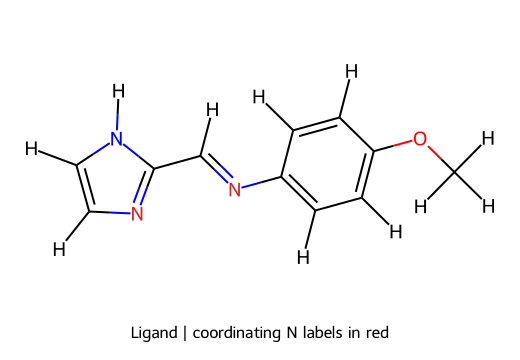

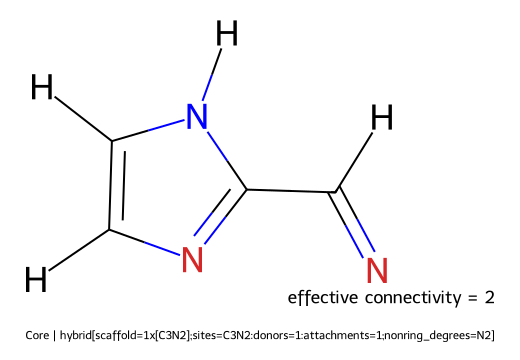

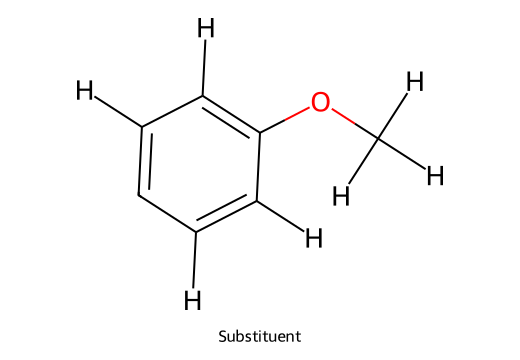

In [5]:
def display_svg_mol(mol, legend, donor_atoms=()):
    donor_atoms = sorted(int(idx) for idx in donor_atoms)
    svg = Draw.MolsToGridImage([mol], molsPerRow=1, subImgSize=(520, 360), legends=[legend], useSVG=True)
    svg_text = svg.data if hasattr(svg, 'data') else str(svg)
    display(SVG(color_atom_labels(svg_text, donor_atoms)))

core_label = core_family_label(core_mol)
labelled_core_mol = Chem.Mol(core_mol)
core_ring_atoms = {idx for ring in labelled_core_mol.GetRingInfo().AtomRings() for idx in ring}
for atom in labelled_core_mol.GetAtoms():
    is_donor = atom.HasProp('_MetalDonor') and atom.GetBoolProp('_MetalDonor')
    if is_donor and (not core_ring_atoms or atom.GetIdx() not in core_ring_atoms):
        atom.SetProp('atomNote', f"effective connectivity = {atom.GetIntProp('_LigandEffectiveDegree')}")

core_donor_atoms = [
    atom.GetIdx() for atom in labelled_core_mol.GetAtoms()
    if atom.HasProp('_MetalDonor') and atom.GetBoolProp('_MetalDonor')
]
display_svg_mol(lig_mol, 'Ligand | coordinating N labels in red', donor_atoms)
display_svg_mol(labelled_core_mol, f'Core | {core_label}', core_donor_atoms)
display_svg_mol(subs_mol, 'Substituent')

## Reading the Core-Family Label

For `ACAHUJ02`, the label starts with `scaffold=1x[C3N2]`. This means that the core contains one metal-connected ring system composed of three carbon and two nitrogen atoms. `C3N2` is therefore a heavy-atom composition label for the selected ring, not a molecular formula: hydrogen atoms, substituents, formal charges and bond multiplicities are not represented in it.

In the `sites` field, `donors=1` indicates that one atom of this ring binds the metal, while `attachments=1` locates the attachment to the acyclic core one ring bond away from that donor. The final `nonring_degrees=N2` field describes the effective connectivity of the metal-bound nitrogen outside the ring. Only this non-ring donor contributes an effective-connectivity term to the hybrid family label; the ring donor does not.

## Highlight Split On Parent Ligand

Green atoms are the core and blue atoms are substituent atoms; the coordinating N labels are shown in red. The lighter core and substituent colors retain the underlying molecular structure. This drawing keeps the original parent ligand connectivity and is useful for deciding whether the split itself is chemically right.

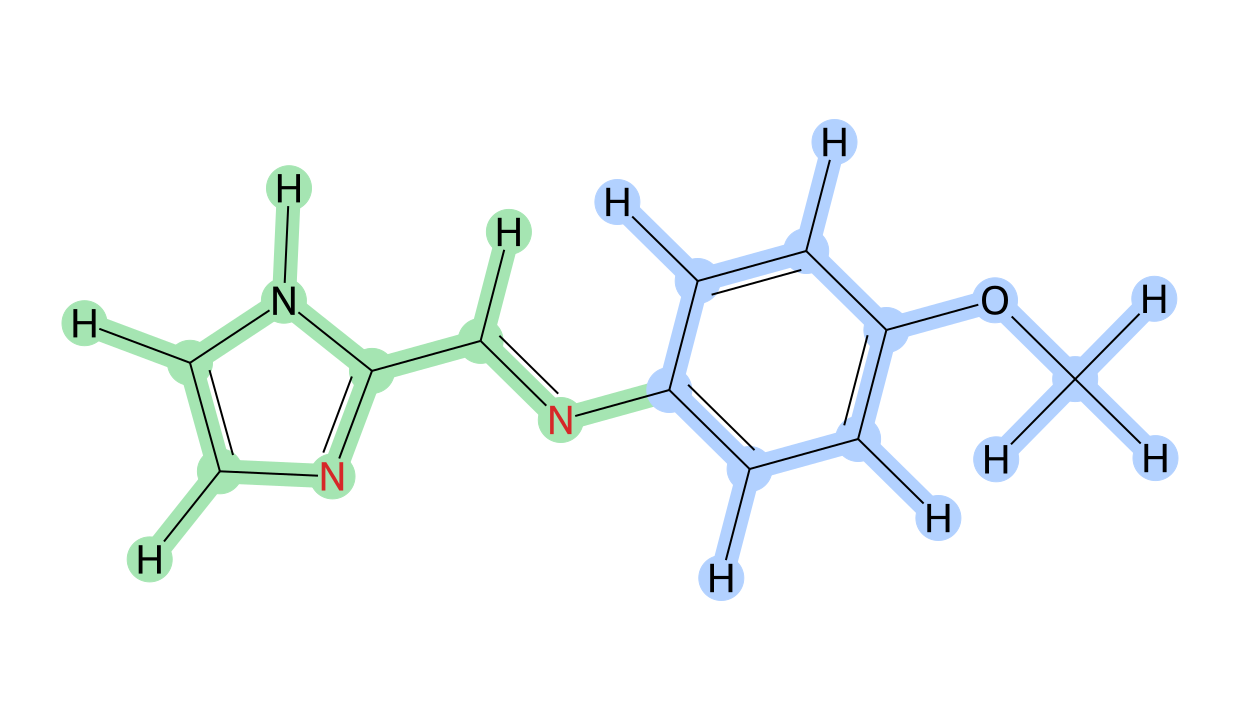

In [6]:
highlight_atoms = sorted(int(idx) for idx in set(core_atoms) | set(subs_atoms))
highlight_colors = {int(idx): (0.65, 0.90, 0.70) for idx in core_atoms}
highlight_colors.update({int(idx): (0.70, 0.82, 1.00) for idx in subs_atoms})
from subprocess import run

svg_path = project_path / 'Figures' / 'ACAHUJ_core_substituent_split.svg'
figure_path = svg_path.with_suffix('.png')
svg = Draw.MolsToGridImage(
    [lig_mol],
    molsPerRow=1,
    subImgSize=(1240, 720),
    highlightAtomLists=[highlight_atoms],
    highlightAtomColors=[highlight_colors],
    useSVG=True,
)
svg_text = svg.data if hasattr(svg, 'data') else str(svg)
svg_text = color_atom_labels(svg_text, donor_atoms)
svg_path.write_text(svg_text)
run(['sips', '-s', 'format', 'png', str(svg_path), '--out', str(figure_path)], check=True, capture_output=True)
display(SVG(svg_text))